# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chứa mã đầy đủ cho từng bước theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [1]:
%pip install -r requirements-colab.txt
%pip install pytest
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Dữ liệu: tải và chia split

In [ ]:
!python scripts/prepare_data.py --kaggle

In [3]:
import json
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

def read_jsonl(path):
    rows = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return rows

# Đọc các split
train_data = read_jsonl('data/splits/train.jsonl')
val_data   = read_jsonl('data/splits/val.jsonl')
test_data  = read_jsonl('data/splits/test.jsonl')
meta       = json.loads(Path('data/splits/meta.json').read_text(encoding='utf-8'))

print(f"dataset_version : {meta['dataset_version']}")
print(f"train : {len(train_data)} ảnh")
print(f"val   : {len(val_data)} ảnh")
print(f"test  : {len(test_data)} ảnh")

# Thống kê số box từng lớp để đối chiếu README/GUIDE
def split_stats(records):
    counts = {label: 0 for label in ('pothole', 'crack', 'manhole')}
    for rec in records:
        for obj in rec['objects']:
            counts[obj['label']] += 1
    return counts

for split_name, records in [('train', train_data), ('val', val_data), ('test', test_data)]:
    print(f"{split_name:5s}: {len(records):4d} ảnh | {split_stats(records)}")

# Kiểm tra không session nào xuất hiện ở 2 split
train_sessions = {r['session'] for r in train_data}
val_sessions   = {r['session'] for r in val_data}
test_sessions  = {r['session'] for r in test_data}
assert train_sessions.isdisjoint(val_sessions),  "LEAK: session xuất hiện ở cả train và val!"
assert train_sessions.isdisjoint(test_sessions), "LEAK: session xuất hiện ở cả train và test!"
assert val_sessions.isdisjoint(test_sessions),   "LEAK: session xuất hiện ở cả val và test!"
print("\nKiểm tra session: OK — không rò rỉ")

dataset_version : d10-21e4070301
train : 1422 ảnh
val   : 276 ảnh
test  : 311 ảnh
train: 1422 ảnh | {'pothole': 1074, 'crack': 1750, 'manhole': 691}
val  :  276 ảnh | {'pothole': 66, 'crack': 470, 'manhole': 103}
test :  311 ảnh | {'pothole': 121, 'crack': 299, 'manhole': 163}

Kiểm tra session: OK — không rò rỉ


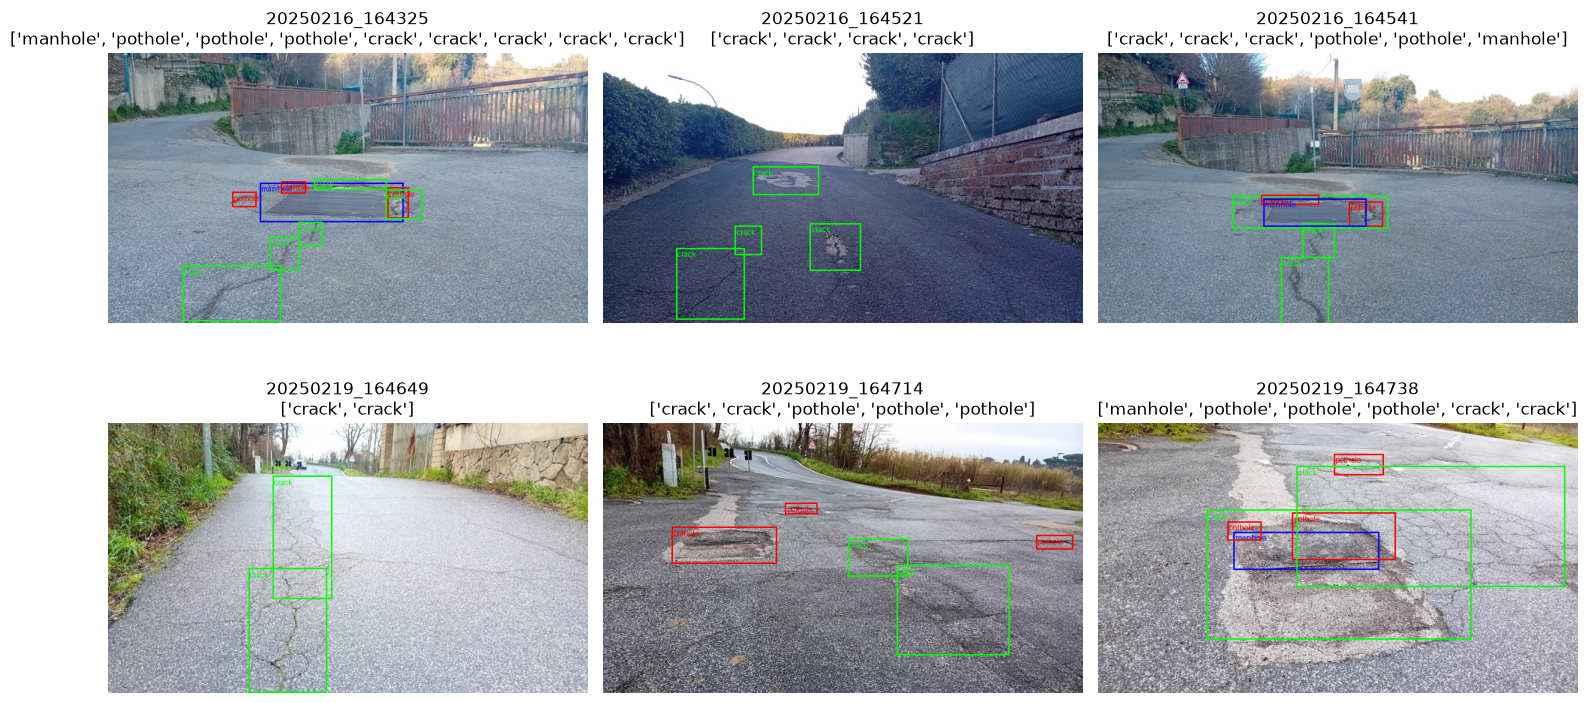

Lưu ảnh mẫu → report/evidence/sample_boxes.png


In [4]:
# Vẽ 6 ảnh có box để xác nhận nhãn
COLOR_MAP = {'pothole': 'red', 'crack': 'lime', 'manhole': 'blue'}

def draw_boxes_yolo(record, data_root='data'):
    img = Image.open(Path(data_root) / record['image_path']).convert('RGB')
    draw = ImageDraw.Draw(img)
    W, H = record['width'], record['height']
    for obj in record['objects']:
        xc, yc, w, h = obj['yolo']
        x1 = (xc - w/2) * W; y1 = (yc - h/2) * H
        x2 = (xc + w/2) * W; y2 = (yc + h/2) * H
        color = COLOR_MAP.get(obj['label'], 'yellow')
        draw.rectangle([x1, y1, x2, y2], outline=color, width=2)
        draw.text((x1+2, y1+2), obj['label'], fill=color)
    return img

samples = [r for r in train_data if r['objects']][:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, rec in zip(axes.flat, samples):
    ax.imshow(draw_boxes_yolo(rec))
    ax.set_title(f"{rec['image_id']}\n{[o['label'] for o in rec['objects']]}")
    ax.axis('off')
plt.tight_layout()
Path('report/evidence').mkdir(parents=True, exist_ok=True)
plt.savefig('report/evidence/sample_boxes.png', dpi=80, bbox_inches='tight')
plt.show()
print("Lưu ảnh mẫu → report/evidence/sample_boxes.png")

## 2. Nhãn: YOLO → JSON thang 0–1000

JSON answer: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


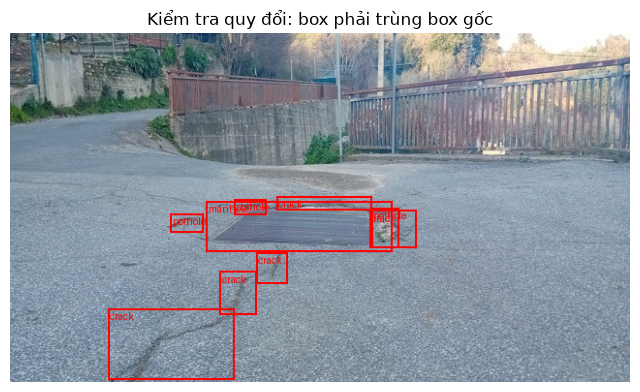

Kiểm tra quy đổi: OK


In [5]:
import json

# ============================================================
# Prompt yêu cầu model trả JSON list, nêu 3 lớp, thang 0–1000
# ============================================================
PROMPT = (
    "Detect all road damage objects in the image. "
    "Return ONLY a JSON array (no extra text) with one object per detection. "
    "Each object must have keys: \"label\" (one of: pothole, crack, manhole) "
    "and \"bbox_2d\" ([x1, y1, x2, y2] as integers on scale 0-1000, "
    "where 0,0 is top-left and 1000,1000 is bottom-right). "
    "If no damage is visible, return []. "
    "Example: [{\"label\": \"pothole\", \"bbox_2d\": [120, 340, 250, 480]}]"
)

def yolo_to_box(label, yolo):
    """Chuyển YOLO (xc, yc, w, h) chuẩn hoá [0,1] → dict thang 0–1000."""
    xc, yc, w, h = yolo
    x1 = int(max(0, min(1000, round((xc - w / 2) * 1000))))
    y1 = int(max(0, min(1000, round((yc - h / 2) * 1000))))
    x2 = int(max(0, min(1000, round((xc + w / 2) * 1000))))
    y2 = int(max(0, min(1000, round((yc + h / 2) * 1000))))
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    """Chuyển danh sách objects → chuỗi JSON thang 0–1000, sắp xếp theo (y1, x1)."""
    boxes = [yolo_to_box(o['label'], o['yolo']) for o in objects]
    # Sắp xếp trên→dưới, trái→phải: thứ tự ổn định cho model học
    boxes.sort(key=lambda b: (b['bbox_2d'][1], b['bbox_2d'][0]))
    return json.dumps(boxes, separators=(',', ':'))

# ============================================================
# Kiểm tra: chuyển nhãn → JSON → quy ngược về pixel → vẽ lại
# ============================================================
from PIL import Image, ImageDraw
from pathlib import Path
import matplotlib.pyplot as plt

rec = next(r for r in train_data if r['objects'])
answer = objects_to_answer(rec['objects'])
print("JSON answer:", answer)

img = Image.open(Path('data') / rec['image_path']).convert('RGB')
draw = ImageDraw.Draw(img)
W, H = rec['width'], rec['height']
for obj in json.loads(answer):
    x1, y1, x2, y2 = obj['bbox_2d']
    # Quy ngược về pixel: chia 1000 rồi nhân W/H
    px1 = x1 / 1000 * W; py1 = y1 / 1000 * H
    px2 = x2 / 1000 * W; py2 = y2 / 1000 * H
    draw.rectangle([px1, py1, px2, py2], outline='red', width=2)
    draw.text((px1+2, py1+2), obj['label'], fill='red')

plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.title('Kiểm tra quy đổi: box phải trùng box gốc')
plt.axis('off')
plt.show()
print("Kiểm tra quy đổi: OK")

## 3. E0: zero-shot

In [ ]:
import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from pathlib import Path
from PIL import Image
import json

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"

# QLoRA 4-bit NF4 — ViT và lm_head KHÔNG lượng tử hoá
# (bắt buộc để E2/E3 có thể huấn luyện projector đầy đủ)
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
    # Transformers so khớp từ đầu tên module; Qwen3-VL dùng prefix model.visual.
    llm_int8_skip_modules=["model.visual", "lm_head"],  # giữ toàn bộ ViT/projector ở fp16
)

model = Qwen3VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    dtype=torch.float16,
    device_map={"": 0},
)
model.eval()

processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.tokenizer.padding_side = "left"  # quan trọng cho batch inference

print("Model nạp xong!")
print(f"VRAM hiện tại: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

C:\Users\PC\K4-Track-4-Day10-VisionLanguageModel\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\PC\K4-Track-4-Day10-VisionLanguageModel\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\PC\.cache\huggingface\hub\models--Qwen--Qwen3-VL-4B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an a

In [ ]:
# Suy luận E0: zero-shot trên toàn bộ test set
# Ghi kết quả vào work/e0.jsonl
from pathlib import Path
from tqdm import tqdm

Path('work').mkdir(exist_ok=True)

BATCH_SIZE = 4
MAX_NEW_TOKENS = 256

def run_inference(dataset, out_path, model, processor, prompt=PROMPT,
                  batch_size=BATCH_SIZE, max_new_tokens=MAX_NEW_TOKENS,
                  data_root='data'):
    """Chạy inference batch, ghi từng dòng JSON vào out_path."""
    Path(out_path).parent.mkdir(parents=True, exist_ok=True)
    results = []

    for start in tqdm(range(0, len(dataset), batch_size), desc=Path(out_path).stem):
        batch_records = dataset[start:start + batch_size]

        # Tạo danh sách messages cho từng ảnh trong batch
        batch_messages = []
        batch_images = []
        for rec in batch_records:
            img = Image.open(Path(data_root) / rec['image_path']).convert('RGB')
            batch_images.append(img)
            messages = [{
                "role": "user",
                "content": [
                    {"type": "image", "image": img},
                    {"type": "text",  "text": prompt},
                ]
            }]
            batch_messages.append(messages)

        # Tokenise cả batch (padding_side='left' quan trọng cho batch sinh)
        inputs = processor.apply_chat_template(
            batch_messages,
            tokenize=True,
            add_generation_prompt=True,
            return_dict=True,
            return_tensors="pt",
            padding=True,
        ).to(model.device)

        prompt_len = inputs["input_ids"].shape[1]

        with torch.no_grad():
            out_ids = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
            )

        # Chỉ decode phần sinh ra (bỏ prompt)
        new_tokens = out_ids[:, prompt_len:]
        raws = processor.batch_decode(new_tokens, skip_special_tokens=True)

        for rec, raw in zip(batch_records, raws):
            results.append({"image_id": rec['image_id'], "raw": raw})

    # Ghi file
    with open(out_path, 'w', encoding='utf-8') as f:
        for r in results:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
    print(f"Đã ghi {len(results)} dòng → {out_path}")
    return results

e0_results = run_inference(test_data, 'work/e0.jsonl', model, processor)

In [ ]:
# In 5 output thô để kiểm tra
for r in e0_results[:5]:
    print(f"[{r['image_id']}] {r['raw'][:200]}")
    print('---')

In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

# E0 không còn cần trên GPU; giải phóng trước khi nạp model cho E1.
import gc
del model
gc.collect()
torch.cuda.empty_cache()

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [1]:
import torch
from pathlib import Path
from PIL import Image

def encode_example(record, prompt, processor, data_root='data'):
    """
    Tạo input_ids + labels cho một ảnh.
    Labels = -100 cho prompt và token ảnh, chỉ học phần trả lời (answer).
    """
    img = Image.open(Path(data_root) / record['image_path']).convert('RGB')
    answer = objects_to_answer(record['objects'])

    user_msg = [{
        "role": "user",
        "content": [
            {"type": "image", "image": img},
            {"type": "text",  "text": prompt},
        ]
    }]
    assistant_msg = user_msg + [{
        "role": "assistant",
        "content": [{"type": "text", "text": answer}]
    }]

    # Encode chỉ prompt → lấy độ dài
    prompt_enc = processor.apply_chat_template(
        user_msg,
        tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt"
    )
    n = prompt_enc["input_ids"].shape[1]

    # Encode chuỗi đầy đủ (prompt + answer)
    full_enc = processor.apply_chat_template(
        assistant_msg,
        tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt"
    )

    # Kiểm tra prompt là tiền tố của chuỗi đầy đủ
    # (bắt buộc theo GUIDE bước 4)
    assert torch.equal(
        full_enc["input_ids"][0, :n],
        prompt_enc["input_ids"][0]
    ), "Prompt không phải tiền tố của full_enc!"

    # Mask: chỉ tính loss trên phần trả lời
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = -100  # bỏ qua prompt và token ảnh

    result = dict(full_enc)
    result["labels"] = labels
    return result


def collate_fn(batch):
    """
    Gộp batch:
    - input_ids / attention_mask / labels: pad đến cùng độ dài (labels đệm = -100)
    - pixel_values / image_grid_thw: cat theo dim 0 (KHÔNG pad)
    """
    max_len = max(b["input_ids"].shape[1] for b in batch)
    pad_tok = processor.tokenizer.pad_token_id or 0

    input_ids_list, attn_list, labels_list = [], [], []
    pixel_list, grid_list = [], []
    mm_token_list = []

    for b in batch:
        seq_len = b["input_ids"].shape[1]
        pad_len = max_len - seq_len

        # Pad từ phía trái (padding_side='left')
        ids = torch.cat([torch.full((1, pad_len), pad_tok, dtype=torch.long),
                         b["input_ids"]], dim=1)
        attn = torch.cat([torch.zeros(1, pad_len, dtype=torch.long),
                          b["attention_mask"]], dim=1)
        lbl = torch.cat([torch.full((1, pad_len), -100, dtype=torch.long),
                         b["labels"]], dim=1)

        input_ids_list.append(ids)
        attn_list.append(attn)
        labels_list.append(lbl)

        if "pixel_values" in b:
            pixel_list.append(b["pixel_values"])
        if "image_grid_thw" in b:
            grid_list.append(b["image_grid_thw"])
        if "mm_token_type_ids" in b:
            mm_ids = torch.cat([torch.zeros(1, pad_len, dtype=torch.long),
                                b["mm_token_type_ids"]], dim=1)
            mm_token_list.append(mm_ids)

    result = {
        "input_ids":      torch.cat(input_ids_list, dim=0),
        "attention_mask": torch.cat(attn_list, dim=0),
        "labels":         torch.cat(labels_list, dim=0),
    }
    if pixel_list:
        result["pixel_values"]    = torch.cat(pixel_list, dim=0)
    if grid_list:
        result["image_grid_thw"]  = torch.cat(grid_list, dim=0)
    if mm_token_list:
        result["mm_token_type_ids"] = torch.cat(mm_token_list, dim=0)
    return result


# ============================================================
# Kiểm tra: số token ảnh phải là 220 cho ảnh 640×360
# ============================================================
sample = encode_example(train_data[0], PROMPT, processor)
prompt_check = processor.apply_chat_template(
    [{'role':'user','content':[{'type':'image','image': Image.open(Path('data')/train_data[0]['image_path'])},
                               {'type':'text','text':PROMPT}]}],
    tokenize=True, add_generation_prompt=True, return_dict=True, return_tensors='pt'
)
image_token_id = processor.tokenizer.convert_tokens_to_ids('<|image_pad|>')
n_image_tokens = (prompt_check['input_ids'] == image_token_id).sum().item()
assert n_image_tokens == 220, f'Kỳ vọng 220 vision token, nhận {n_image_tokens}'
n_answer_tokens = (sample['labels'] != -100).sum().item()
print(f"Vision tokens  : {n_image_tokens}")
print(f"Prompt length  : {prompt_check['input_ids'].shape[1]} tokens")
print(f"Answer tokens  : {n_answer_tokens}")

# Kiểm tra giải mã phần answer
answer_ids = sample['input_ids'][0][sample['labels'][0] != -100]
decoded = processor.tokenizer.decode(answer_ids, skip_special_tokens=False)
print(f"Answer decoded : {decoded}")

NameError: name 'train_data' is not defined

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
import re
from peft import LoraConfig, get_peft_model

# Regex target modules theo GUIDE bước 5
LLM_TARGETS = [
    # 36 layers × (q,k,v,o)_proj = 144
    r"(?:^|\.)language_model\.layers\.\d+\.self_attn\.(q_proj|k_proj|v_proj|o_proj)$",
    # 36 layers × (gate,up,down)_proj = 108  → total 252
    r"(?:^|\.)language_model\.layers\.\d+\.mlp\.(gate_proj|up_proj|down_proj)$",
]
VIT_TARGETS = [
    # 24 blocks × (qkv, proj) = 48
    r"(?:^|\.)visual\.blocks\.\d+\.attn\.(qkv|proj)$",
    # 24 blocks × (linear_fc1, linear_fc2) = 48  → total 96
    r"(?:^|\.)visual\.blocks\.\d+\.mlp\.(linear_fc1|linear_fc2)$",
]

PROJECTOR_NAMES = ["visual.merger", "visual.deepstack_merger_list"]


def apply_setup(model, setup: str, r=16, lora_alpha=32, lora_dropout=0.05):
    """
    Áp dụng setup LoRA và đóng băng.
    setup: 'E1' | 'E2' | 'E3'
    Trả về peft_model.
    """
    # 1. Đóng băng toàn bộ tham số
    for param in model.parameters():
        param.requires_grad = False

    # 2. Xác định target modules
    if setup in ('E1', 'E2'):
        target_patterns = LLM_TARGETS
    else:  # E3
        target_patterns = LLM_TARGETS + VIT_TARGETS

    # Thu thập tên module khớp pattern
    all_module_names = [name for name, _ in model.named_modules()]
    target_modules = []
    for name in all_module_names:
        for pat in target_patterns:
            if re.search(pat, name):
                target_modules.append(name)
                break

    # Truyền đúng tên module đầy đủ để PEFT không vô tình gắn LoRA vào module khác
    expected = 252 if setup in ('E1', 'E2') else 348
    assert len(target_modules) == expected, (
        f'{setup}: khớp {len(target_modules)}/{expected} module; hãy in model.named_modules() để kiểm tra cây model'
    )
    print(f"[{setup}] Matched LoRA modules: {len(target_modules)}")

    # 3. Tạo LoRA config
    lora_config = LoraConfig(
        r=r,
        lora_alpha=lora_alpha,
        lora_dropout=lora_dropout,
        target_modules=target_modules,
        bias="none",
        task_type="CAUSAL_LM",
    )

    # 4. Bọc model bằng PEFT (tự bật requires_grad cho LoRA params)
    peft_model = get_peft_model(model, lora_config)
    peft_model.enable_input_require_grads()  # cần cho gradient checkpointing

    # 5. Mở projector (E2 và E3): đưa về float32 và bật requires_grad
    if setup in ('E2', 'E3'):
        quantized_projector = [name for name, module in peft_model.named_modules()
                               if any(pn in name for pn in PROJECTOR_NAMES)
                               and module.__class__.__name__ == 'Linear4bit']
        assert not quantized_projector, (
            'Projector đang bị quantize 4-bit. Hãy dùng '
            'llm_int8_skip_modules=["model.visual", "lm_head"] rồi nạp lại model. '
            f'Ví dụ: {quantized_projector[:2]}'
        )
        n_proj_tensors = 0
        n_proj_params = 0
        for name, param in peft_model.named_parameters():
            if any(pn in name for pn in PROJECTOR_NAMES):
                param.data = param.data.float()  # float32 để tránh lỗi lượng tử
                param.requires_grad = True
                n_proj_tensors += 1
                n_proj_params += param.numel()
        assert n_proj_params > 100_000_000, f'Projector chỉ có {n_proj_params:,} params — sai tên module?'
        print(f"[{setup}] Projector mở: {n_proj_tensors} tensors / {n_proj_params:,} params")

    # 6. In tổng số tham số
    trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in peft_model.parameters())
    print(f"[{setup}] Trainable params: {trainable:,} / {total:,} "
          f"({100*trainable/total:.2f}%)")
    return peft_model


print("apply_setup() đã định nghĩa — sẽ dùng trong bước 6.")

## 6. Vòng huấn luyện

In [ ]:
import math
import time
import json
from pathlib import Path
from torch.amp import GradScaler, autocast
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from transformers import get_cosine_schedule_with_warmup

class RoadDamageDataset(Dataset):
    def __init__(self, records, prompt, processor, data_root='data', fraction=1.0, seed=42):
        import random
        rng = random.Random(seed)
        if fraction < 1.0:
            k = max(1, int(len(records) * fraction))
            records = rng.sample(records, k)
        self.records = records
        self.prompt = prompt
        self.processor = processor
        self.data_root = data_root

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        return encode_example(self.records[idx], self.prompt, self.processor, self.data_root)


def save_extra_trainable(peft_model, adapter_dir):
    """Lưu riêng các tham số projector (E2/E3) vì peft chỉ lưu LoRA adapter."""
    extra = {}
    for name, param in peft_model.named_parameters():
        if any(pn in name for pn in PROJECTOR_NAMES) and param.requires_grad:
            extra[name] = param.detach().cpu()
    if extra:
        torch.save(extra, Path(adapter_dir) / "extra_trainable.pt")
        print(f"Lưu {len(extra)} projector params → {adapter_dir}/extra_trainable.pt")


def train_one_setup(setup: str, train_records, adapter_dir,
                    lr=2e-4, batch_size=2, grad_accum=4, max_steps=300,
                    seed=42, data_fraction=1.0, lora_r=16, lora_alpha=32):
    """
    Chạy toàn bộ vòng huấn luyện cho một setup (E1/E2/E3).
    Trả về dict meta: trainable_params, peak_vram_gb, train_minutes.
    """
    import gc
    torch.manual_seed(seed)
    torch.cuda.reset_peak_memory_stats()

    # ── Nạp model gốc ──────────────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"  Bắt đầu {setup}")
    print(f"{'='*60}")

    base_model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quantization_config,
        dtype=torch.float16,
        device_map={"": 0},
    )

    # ── Áp dụng LoRA ───────────────────────────────────────────────────
    peft_model = apply_setup(base_model, setup, r=lora_r, lora_alpha=lora_alpha)
    peft_model.config.use_cache = False
    peft_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    trainable_params = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)

    # ── DataLoader ─────────────────────────────────────────────────────
    dataset = RoadDamageDataset(train_records, PROMPT, processor,
                                fraction=data_fraction, seed=seed)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True,
                        collate_fn=collate_fn, num_workers=0, pin_memory=False)

    # ── Optimiser + LR scheduler ────────────────────────────────────────
    trainable_params_list = [p for p in peft_model.parameters() if p.requires_grad]
    optimizer = AdamW(trainable_params_list, lr=lr, weight_decay=0)

    total_optim_steps = max_steps
    warmup_steps = int(0.05 * total_optim_steps)
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=warmup_steps,
        num_training_steps=total_optim_steps
    )
    scaler = GradScaler("cuda")

    # ── Vòng train ─────────────────────────────────────────────────────
    Path(adapter_dir).mkdir(parents=True, exist_ok=True)
    peft_model.train()
    step = 0
    t_start = time.time()

    loader_iter = iter(loader)
    while step < max_steps:
        # Một optimizer step dùng grad_accum micro-batch KHÁC NHAU.
        optimizer.zero_grad(set_to_none=True)
        accum_loss = 0.0

        for _ in range(grad_accum):
            try:
                micro_batch = next(loader_iter)
            except StopIteration:
                loader_iter = iter(loader)
                micro_batch = next(loader_iter)

            batch = {k: v.to(peft_model.device) for k, v in micro_batch.items()}
            with autocast('cuda', dtype=torch.float16):
                raw_loss = peft_model(**batch).loss
                loss = raw_loss / grad_accum

            if not math.isfinite(raw_loss.item()):
                raise FloatingPointError(
                    f'loss={raw_loss.item()} tại step {step}; kiểm tra mask, dữ liệu và learning rate'
                )

            scaler.scale(loss).backward()
            accum_loss += raw_loss.item()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable_params_list, 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        step += 1
        accum_loss /= grad_accum

        if step % 50 == 0 or step == 1:
            vram_gb = torch.cuda.memory_allocated() / 1e9
            print(f"  step {step:4d}/{max_steps}  loss={accum_loss:.4f}  "
                  f"lr={scheduler.get_last_lr()[0]:.2e}  VRAM={vram_gb:.1f}GB")

        # Lưu checkpoint mỗi 100 bước
        if step % 100 == 0:
            ckpt = Path(adapter_dir) / f"checkpoint-{step}"
            peft_model.save_pretrained(str(ckpt))
            save_extra_trainable(peft_model, str(ckpt))

    # ── Lưu adapter cuối ───────────────────────────────────────────────
    peft_model.save_pretrained(adapter_dir)
    save_extra_trainable(peft_model, adapter_dir)

    peak_vram_gb   = torch.cuda.max_memory_allocated() / 1e9
    train_minutes  = (time.time() - t_start) / 60

    meta = {
        "trainable_params": trainable_params,
        "peak_vram_gb":     round(peak_vram_gb, 2),
        "train_minutes":    round(train_minutes, 1),
    }
    (Path(adapter_dir) / "run.json").write_text(
        json.dumps(meta, indent=2), encoding='utf-8'
    )
    print(f"\n{setup} xong! VRAM đỉnh={peak_vram_gb:.1f}GB  thời gian={train_minutes:.1f} phút")

    # Giải phóng VRAM
    del peft_model, base_model
    gc.collect()
    torch.cuda.empty_cache()

    return meta


print("train_one_setup() đã định nghĩa — sẵn sàng chạy E1/E2/E3")

In [ ]:
import json

with open("work/adapters/e1/run.json", encoding="utf-8") as f:
    meta_e1 = json.load(f)

with open("work/adapters/e2/run.json", encoding="utf-8") as f:
    meta_e2 = json.load(f)

In [ ]:
# ── Chạy E1: LoRA chỉ LLM ─────────────────────────────────────────────
meta_e1 = train_one_setup(
    setup='E1',
    train_records=train_data,
    adapter_dir='work/adapters/e1',
    lr=2e-4, batch_size=2, grad_accum=4, max_steps=300, seed=42,
)

In [ ]:
# ── Chạy E2: E1 + projector đầy đủ ───────────────────────────────────
meta_e2 = train_one_setup(
    setup='E2',
    train_records=train_data,
    adapter_dir='work/adapters/e2',
    lr=2e-4, batch_size=2, grad_accum=4, max_steps=300, seed=42,
)

In [ ]:
# ── Chạy E3: E2 + LoRA ViT ────────────────────────────────────────────
meta_e3 = train_one_setup(
    setup='E3',
    train_records=train_data,
    adapter_dir='work/adapters/e3',
    lr=2e-4, batch_size=2, grad_accum=4, max_steps=300, seed=42,
)

## 7. Suy luận và chấm E1–E3

In [ ]:
import gc
import subprocess
import sys
from peft import PeftModel

def load_trained_model(adapter_dir, is_trainable=False):
    """
    Nạp model gốc 4-bit → nạp LoRA adapter → nạp lại projector nếu có.
    """
    base = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quantization_config,
        dtype=torch.float16,
        device_map={"": 0},
    )
    peft_model = PeftModel.from_pretrained(base, adapter_dir, is_trainable=is_trainable)
    peft_model.eval()

    # Nạp lại projector (E2/E3) — bắt buộc nếu không muốn E2/E3 ≈ E1
    extra_path = Path(adapter_dir) / "extra_trainable.pt"
    if extra_path.exists():
        extra = torch.load(str(extra_path), map_location="cuda:0", weights_only=True)
        param_dict = dict(peft_model.named_parameters())
        loaded = 0
        for name, tensor in extra.items():
            if name in param_dict:
                param_dict[name].data.copy_(tensor.to(param_dict[name].dtype))
                loaded += 1
        assert loaded == len(extra), f'Chỉ nạp được {loaded}/{len(extra)} projector tensors'
        print(f"Nạp lại {loaded} projector params từ {extra_path}")
    else:
        print("Không có extra_trainable.pt — đây là E1 (projector đóng băng)")

    return peft_model


def score_predictions(setup_name, pred_path, out_path, meta=None):
    """Gọi trọng tài score.py; dừng ngay nếu lệnh chấm lỗi."""
    command = [sys.executable, 'scripts/score.py', '--pred', pred_path,
               '--name', setup_name, '--out', out_path]
    for key, value in (meta or {}).items():
        command.extend(['--meta', f'{key}={value}'])
    subprocess.run(command, check=True)


def run_and_score(setup_name, adapter_dir, meta):
    """Nạp model đã train, inference test set, chấm và lưu evidence JSON."""
    print(f"\n--- Inference {setup_name} ---")
    trained = load_trained_model(adapter_dir)

    pred_path = f"work/{setup_name.lower()}.jsonl"
    run_inference(test_data, pred_path, trained, processor)

    del trained
    gc.collect()
    torch.cuda.empty_cache()

    # Chấm bằng subprocess để lỗi từ score.py làm cell dừng ngay.
    out_path  = f"report/evidence/{setup_name.lower()}.json"
    score_predictions(setup_name, pred_path, out_path, meta)


# Chạy inference + chấm cho E1, E2, E3
run_and_score('E1', 'work/adapters/e1', meta_e1)
run_and_score('E2', 'work/adapters/e2', meta_e2)
run_and_score('E3', 'work/adapters/e3', meta_e3)

In [ ]:
# Đọc và in bảng kết quả tổng hợp E0–E3
import json
from pathlib import Path

print(f"{'Setup':<6} {'F1':>6} {'CI95':>15} {'FP/img':>7} "
      f"{'P(hole)':>8} {'P(crack)':>8} {'P(manhole)':>10} "
      f"{'VRAM':>6} {'Min':>6} {'Params':>12}")
print('-' * 90)

for name in ['e0', 'e1', 'e2', 'e3']:
    p = Path(f'report/evidence/{name}.json')
    if not p.exists():
        print(f"{name.upper():<6} (chưa có)")
        continue
    d = json.loads(p.read_text(encoding='utf-8'))
    m  = d['micro']
    ci = d['f1_ci95']
    pc = d['per_class']
    mt = d.get('meta', {})
    vram = f"{mt['peak_vram_gb']:.2f}" if 'peak_vram_gb' in mt else '-'
    mins = f"{mt['train_minutes']:.1f}" if 'train_minutes' in mt else '-'
    params = f"{mt['trainable_params']:,}" if 'trainable_params' in mt else '0'
    print(f"{name.upper():<6} {m['f1']:>6.3f} [{ci[0]:.3f},{ci[1]:.3f}] "
          f"{d['fp_per_image']:>7.2f} "
          f"{pc['pothole']['f1']:>8.3f} {pc['crack']['f1']:>8.3f} {pc['manhole']['f1']:>10.3f} "
          f"{vram:>6} {mins:>6} {params:>12}")

In [ ]:
# Ảnh minh hoạ: vẽ dự đoán vs ground-truth cho ≥ 6 ảnh (bắt buộc cho rubric B)
import json
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '.')
from scripts.score import parse_output, _gt_boxes, _match

# Đọc predictions tốt nhất (E1 hoặc E2/E3)
best_preds_path = 'work/e1.jsonl'  # thay bằng setup tốt nhất sau khi chấm
preds = {}
for row in read_jsonl(best_preds_path):
    preds[row['image_id']] = row['raw']

# Tự chọn 3 ảnh dự đoán hoàn toàn đúng và 3 ảnh có FP/FN.
def one_image_stats(rec):
    parsed = parse_output(preds.get(rec['image_id'], ''))
    per_class, _ = _match(_gt_boxes(rec), parsed if parsed is not None else [])
    return tuple(sum(v[i] for v in per_class.values()) for i in range(3))  # TP, FP, FN

stats_by_id = {rec['image_id']: one_image_stats(rec) for rec in test_data}
correct_recs = [r for r in test_data if stats_by_id[r['image_id']][0] > 0
                and stats_by_id[r['image_id']][1:] == (0, 0)][:3]
error_recs = [r for r in test_data if sum(stats_by_id[r['image_id']][1:]) > 0][:3]
sample_recs = correct_recs + error_recs
assert len(sample_recs) == 6, 'Không đủ 3 ảnh đúng + 3 ảnh sai; hãy nới tiêu chí chọn ảnh'
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, rec in zip(axes.flat, sample_recs):
    img = Image.open(Path('data') / rec['image_path']).convert('RGB')
    draw = ImageDraw.Draw(img)
    W, H = rec['width'], rec['height']

    # Ground-truth (xanh lá)
    for obj in rec['objects']:
        xc, yc, w, h = obj['yolo']
        x1, y1 = (xc-w/2)*W, (yc-h/2)*H
        x2, y2 = (xc+w/2)*W, (yc+h/2)*H
        draw.rectangle([x1,y1,x2,y2], outline='lime', width=3)
        draw.text((x1+2, y1+2), f"GT:{obj['label']}", fill='lime')

    # Dự đoán (đỏ)
    raw = preds.get(rec['image_id'], '')
    parsed = parse_output(raw)
    if parsed:
        for obj in parsed:
            x1,y1,x2,y2 = [v/1000*W if i%2==0 else v/1000*H
                            for i,v in enumerate(obj['bbox'])]
            draw.rectangle([x1,y1,x2,y2], outline='red', width=2)
            draw.text((x1+2, y2-14), f"P:{obj['label']}", fill='red')

    ax.imshow(img)
    tp, fp, fn = stats_by_id[rec['image_id']]
    status = 'ĐÚNG' if fp == 0 and fn == 0 else 'SAI'
    ax.set_title(f"{status} | TP={tp}, FP={fp}, FN={fn}\n{rec['image_id'][:24]}")
    ax.axis('off')

plt.suptitle('Xanh=GT  Đỏ=Dự đoán', fontsize=14)
plt.tight_layout()
Path('report/evidence').mkdir(parents=True, exist_ok=True)
plt.savefig('report/evidence/predictions_viz.png', dpi=80, bbox_inches='tight')
plt.show()
print("Lưu → report/evidence/predictions_viz.png")

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# ─────────────────────────────────────────────────────────────────────
# E4: Ablation — đổi ĐÚNG MỘT biến: rank (r=4 vs r=64)
#     Tự chọn setup có F1 cao nhất trong E1–E3 làm base.
# ─────────────────────────────────────────────────────────────────────

def evidence_f1(setup):
    p = Path(f'report/evidence/{setup.lower()}.json')
    return json.loads(p.read_text(encoding='utf-8'))['micro']['f1']

E4_BASE_SETUP = max(('E1', 'E2', 'E3'), key=evidence_f1)
print(f'E4 giữ nguyên setup tốt nhất: {E4_BASE_SETUP}; chỉ thay đổi LoRA rank')

# E4a: rank = 4  (alpha = 2*r = 8)
meta_e4_r4 = train_one_setup(
    setup=E4_BASE_SETUP,
    train_records=train_data,
    adapter_dir='work/adapters/e4_rank_4',
    lr=2e-4, batch_size=2, grad_accum=4, max_steps=300, seed=42,
    lora_r=4, lora_alpha=8,
)

# E4b: rank = 64  (alpha = 2*r = 128)
meta_e4_r64 = train_one_setup(
    setup=E4_BASE_SETUP,
    train_records=train_data,
    adapter_dir='work/adapters/e4_rank_64',
    lr=2e-4, batch_size=2, grad_accum=4, max_steps=300, seed=42,
    lora_r=64, lora_alpha=128,
)

In [ ]:
# Inference + chấm E4a (rank=4)
trained_e4r4 = load_trained_model('work/adapters/e4_rank_4')
run_inference(test_data, 'work/e4_rank_4.jsonl', trained_e4r4, processor)
del trained_e4r4; gc.collect(); torch.cuda.empty_cache()

score_predictions('E4_rank_4', 'work/e4_rank_4.jsonl',
                  'report/evidence/e4_rank_4.json', meta_e4_r4)

In [ ]:
# Inference + chấm E4b (rank=64)
trained_e4r64 = load_trained_model('work/adapters/e4_rank_64')
run_inference(test_data, 'work/e4_rank_64.jsonl', trained_e4r64, processor)
del trained_e4r64; gc.collect(); torch.cuda.empty_cache()

score_predictions('E4_rank_64', 'work/e4_rank_64.jsonl',
                  'report/evidence/e4_rank_64.json', meta_e4_r64)

In [ ]:
# In so sánh E4
print("E4 Ablation — biến: lora_rank")
print(f"{'Setup':<15} {'F1':>6} {'CI95':>15} {'Params':>12}")
print('-' * 50)
for name, label in [('e4_rank_4','rank=4'), ('e4_rank_64','rank=64')]:
    p = Path(f'report/evidence/{name}.json')
    if not p.exists(): continue
    d = json.loads(p.read_text(encoding='utf-8'))
    ci = d['f1_ci95']
    print(f"{label:<15} {d['micro']['f1']:>6.3f} [{ci[0]:.3f},{ci[1]:.3f}] "
          f"{d['meta'].get('trainable_params',''):>12,}")

In [ ]:
# ─────────────────────────────────────────────────────────────────────
# E5 (tuỳ chọn, +10 điểm): GRPO với reward IoU
# ─────────────────────────────────────────────────────────────────────

import sys
sys.path.insert(0, '.')
from scripts.score import parse_output, iou_xyxy


def reward_iou(completion: str, gt_boxes: list) -> float:
    """
    Reward = 0.2 + 0.8 * sum_matched_iou / max(n_gt, n_pred, 1)
    - JSON hỏng → 0.0
    - Không GT và không pred → 1.0
    - Box bịa bị phạt qua mẫu số (max n_pred)
    """
    parsed = parse_output(completion)
    if parsed is None:
        return 0.0  # JSON hỏng

    n_gt   = len(gt_boxes)
    n_pred = len(parsed)

    if n_gt == 0 and n_pred == 0:
        return 1.0  # hoàn hảo khi không có object

    # Ghép đôi tham lam: cùng lớp, IoU giảm dần, chỉ nhận IoU ≥ 0.5
    total_iou = 0.0
    classes = set(b['label'] for b in gt_boxes) | set(b['label'] for b in parsed)
    for cls in classes:
        g = [b['bbox'] for b in gt_boxes if b['label'] == cls]
        p = [b['bbox'] for b in parsed  if b['label'] == cls]
        pairs = sorted(
            ((iou_xyxy(gi, pi), i, j) for i, gi in enumerate(g) for j, pi in enumerate(p)),
            key=lambda x: -x[0]
        )
        used_g, used_p = set(), set()
        for iou_val, gi, pi in pairs:
            if iou_val < 0.5:
                break
            if gi in used_g or pi in used_p:
                continue
            used_g.add(gi); used_p.add(pi)
            total_iou += iou_val

    return 0.2 + 0.8 * total_iou / max(n_gt, n_pred, 1)


# ── Unit tests cho reward (chạy được không cần GPU) ─────────────────
def _gt(label, x1, y1, x2, y2):
    return {'label': label, 'bbox': (x1, y1, x2, y2)}

# Test 1: JSON hỏng → 0.0
assert reward_iou("not json", [_gt('pothole',100,100,200,200)]) == 0.0

# Test 2: hoàn hảo (pred == gt) → gần 1.0
perfect = '[{"label":"pothole","bbox_2d":[100,100,200,200]}]'
r = reward_iou(perfect, [_gt('pothole',100,100,200,200)])
assert abs(r - 1.0) < 1e-9, f"Expected 1.0, got {r}"

# Test 3: sai lớp → không khớp → total_iou=0 → 0.2
wrong_cls = '[{"label":"crack","bbox_2d":[100,100,200,200]}]'
r = reward_iou(wrong_cls, [_gt('pothole',100,100,200,200)])
assert abs(r - 0.2) < 1e-9

# Test 4: thừa box (reward hacking) → mẫu số lớn hơn → reward thấp hơn
extra_boxes = '[{"label":"pothole","bbox_2d":[100,100,200,200]},{"label":"pothole","bbox_2d":[300,300,500,500]},{"label":"pothole","bbox_2d":[10,10,900,900]}]'
r_extra = reward_iou(extra_boxes, [_gt('pothole',100,100,200,200)])
r_exact = reward_iou(perfect, [_gt('pothole',100,100,200,200)])
assert r_extra < r_exact, f"Thừa box phải bị phạt: {r_extra} < {r_exact}"

# Test 5: cả hai rỗng → 1.0
assert reward_iou('[]', []) == 1.0

# Test 6: bỏ sót toàn bộ GT nhưng JSON hợp lệ → chỉ nhận điểm định dạng 0.2
assert abs(reward_iou('[]', [_gt('crack',10,10,20,20)]) - 0.2) < 1e-9

print("Tất cả tests reward_iou: PASS ✓")

In [ ]:
# ── GRPO training (E5) ───────────────────────────────────────────────
# Khởi tạo từ adapter tốt nhất (E1/E2/E3)
from trl import GRPOConfig, GRPOTrainer
from datasets import Dataset as HFDataset
import shutil

BEST_SETUP = max(('E1', 'E2', 'E3'), key=evidence_f1)
BEST_ADAPTER = f'work/adapters/{BEST_SETUP.lower()}'
print(f'E5 khởi tạo từ {BEST_SETUP}: {BEST_ADAPTER}')

# Nạp LoRA ở chế độ trainable; load_trained_model cũng phục hồi projector E2/E3.
grpo_model = load_trained_model(BEST_ADAPTER, is_trainable=True)

# Chuẩn bị dataset cho GRPO
def make_grpo_example(rec, prompt=PROMPT, data_root='data'):
    """Trả về prompt text và gt_boxes để dùng trong reward."""
    img = Image.open(Path(data_root) / rec['image_path']).convert('RGB')
    messages = [{'role':'user','content':[{'type':'image','image':img},
                                          {'type':'text','text':prompt}]}]
    prompt_text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    gt_boxes = []
    for obj in rec['objects']:
        xc, yc, w, h = obj['yolo']
        gt_boxes.append({'label': obj['label'],
                         'bbox': ((xc-w/2)*1000, (yc-h/2)*1000,
                                  (xc+w/2)*1000, (yc+h/2)*1000)})
    return {'prompt': prompt_text, 'image': img, 'gt_boxes': gt_boxes}

grpo_records = [make_grpo_example(r) for r in train_data]
grpo_dataset = HFDataset.from_list(grpo_records)

def reward_fn(completions, gt_boxes, **kwargs):
    # prompt là chuỗi chuẩn nên completions cũng là list[str].
    return [reward_iou(completion, gt) for completion, gt in zip(completions, gt_boxes)]

# Config theo e5.yaml: num_generations=4, max_completion_length=128, 60 steps
grpo_config = GRPOConfig(
    num_generations=4,
    max_completion_length=128,
    max_steps=60,
    learning_rate=5e-6,
    beta=0.0,
    output_dir='work/adapters/e5',
    use_vllm=False,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    fp16=True,
    logging_steps=10,
)

trainer = GRPOTrainer(
    model=grpo_model,
    args=grpo_config,
    train_dataset=grpo_dataset,
    reward_funcs=reward_fn,
    processing_class=processor,
)
trainer.train()
grpo_model.save_pretrained('work/adapters/e5')

# Nếu base tốt nhất là E2/E3, giữ lại projector đã SFT (GRPO chỉ cập nhật LoRA).
source_extra = Path(BEST_ADAPTER) / 'extra_trainable.pt'
if source_extra.exists():
    shutil.copy2(source_extra, Path('work/adapters/e5') / source_extra.name)
del trainer, grpo_model
gc.collect()
torch.cuda.empty_cache()
print("E5 GRPO xong!")

In [ ]:
# Inference + chấm E5
e5_model = load_trained_model('work/adapters/e5')
run_inference(test_data, 'work/e5.jsonl', e5_model, processor)
del e5_model; gc.collect(); torch.cuda.empty_cache()

score_predictions('E5', 'work/e5.jsonl', 'report/evidence/e5.json')

In [ ]:
# Kiểm tra bài nộp cuối
!python scripts/check_submission.py